In [1]:
import os
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
import warnings as warn

import pickle

import networkx as nx
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from typing import Any

# ==============================================================================
# SECTION 1: ENVIRONMENT AND LIBRARIES SETUP
# ==============================================================================

In [2]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.5
})

warn.filterwarnings("ignore", category=UserWarning)

In [3]:
BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "data"
GRAPHS_DIR = DATA_DIR / "graphs"
SERVICES_CSV = DATA_DIR / "services.csv"

COOC_THRESHOLD = 3

# ==============================================================================
# SECTION 2: DATASET AND SERVICES CATALOG LOADING
# ==============================================================================

In [4]:
def load_services_catalog(csv_path: Path) -> pl.DataFrame:
    if not csv_path.exists():
        raise FileNotFoundError(f"File not found: {csv_path}")

    df_services = pl.read_csv(csv_path)

    df_services = df_services.with_columns([
        pl.col("name").str.strip_chars().alias("service_name"),
        pl.col("capability").str.strip_chars().alias("capability"),
        pl.col("is_aws").cast(pl.Boolean).alias("is_aws")
    ])

    return df_services

def load_usable_graphml_dataset(graphs_dir: Path) -> dict[str, nx.MultiDiGraph]:
    if not graphs_dir.exists():
        raise FileNotFoundError(f"Graph directory not found: {graphs_dir}")

    graphs_dict = {}
    total_files = 0
    discarded_files = 0

    for graphml_file in graphs_dir.glob("*.graphml"):
        total_files += 1
        arch_id = graphml_file.stem
        try:
            G = nx.read_graphml(graphml_file)

            usable_attr = str(G.graph.get("graph_usable", "False")).strip().lower()

            if usable_attr == "true":
                graphs_dict[arch_id] = G
            else:
                discarded_files += 1

        except Exception as e:
            print(f"⚠️ Error loading {graphml_file.name}: {e}")
            discarded_files += 1

    print(f" Graph loading finished:")
    print(f"   - Files processed: {total_files}")
    print(f"   - Usable architectures loaded: {len(graphs_dict)}[cite: 1]")
    print(f"   - Discarded/unusable architectures: {discarded_files}[cite: 1]")

    return graphs_dict

In [5]:
df_services = load_services_catalog(SERVICES_CSV)
raw_graphs = load_usable_graphml_dataset(GRAPHS_DIR)

print("\nPreview of the services catalog (Polars DataFrame):")
print(df_services.select(["service_name", "capability", "is_aws"]).head(5))

 Graph loading finished:
   - Files processed: 396
   - Usable architectures loaded: 340[cite: 1]
   - Discarded/unusable architectures: 56[cite: 1]

Preview of the services catalog (Polars DataFrame):
shape: (5, 3)
┌──────────────────────┬────────────┬────────┐
│ service_name         ┆ capability ┆ is_aws │
│ ---                  ┆ ---        ┆ ---    │
│ str                  ┆ str        ┆ bool   │
╞══════════════════════╪════════════╪════════╡
│ Transcribe           ┆ compute    ┆ true   │
│ LookoutForVision     ┆ compute    ┆ true   │
│ PrivateLink          ┆ networking ┆ true   │
│ SystemsManager       ┆ control    ┆ true   │
│ UserCompanyDeveloper ┆ User       ┆ false  │
└──────────────────────┴────────────┴────────┘


# ==============================================================================
# SECTION 3: MODULAR EXTRACTION AND TOPOLOGICAL NORMALIZATION
# ==============================================================================


In [6]:
def extract_architecture_metadata(arch_id: str, G: nx.MultiDiGraph) -> dict[str, Any]:
    graph_data = G.graph
    return {
        "arch_id": arch_id,
        "name": str(graph_data.get("name", "Unknown")),
        "link": str(graph_data.get("link", "")),
        "categories": str(graph_data.get("categories", "other")),
        "notes": str(graph_data.get("notes", "")),
        "num_nodes": G.number_of_nodes(),
        "num_edges": G.number_of_edges()
    }

def extract_nodes_metadata(arch_id: str, G: nx.MultiDiGraph) -> list[dict[str, Any]]:
    nodes_records = []
    for node_id in G.nodes():
        data = G.nodes[node_id]
        if not isinstance(data, dict):
            data = {}
        service_name = str(data.get("service", node_id)).strip()
        nodes_records.append({
            "arch_id": arch_id,
            "node_id": str(node_id),
            "service": service_name,
            "custom_name": str(data.get("name", "")),
            "notes": str(data.get("notes", ""))
        })
    return nodes_records

def extract_edges_metadata(arch_id: str, G: nx.MultiDiGraph) -> list[dict[str, Any]]:
    edges_records = []
    for u in G.nodes():
        nbrs = G[u]
        for v, keydict in nbrs.items():
            for key, data in keydict.items():
                if not isinstance(data, dict):
                    data = {}
                edges_records.append({
                    "arch_id": arch_id,
                    "source": str(u),
                    "target": str(v),
                    "edge_key": str(key),
                    "flow_id": str(data.get("flow_id", "0")),
                    "seq": str(data.get("seq", "0")),
                    "type": str(data.get("type", "unknown")),
                    "notes": str(data.get("notes", ""))
                })
    return edges_records

def process_all_graphs(graphs_dict: dict[str, nx.MultiDiGraph]) -> tuple[list, list, list]:
    all_archs = []
    all_nodes = []
    all_edges = []

    for arch_id, G in graphs_dict.items():
        all_archs.append(extract_architecture_metadata(arch_id, G))
        all_nodes.extend(extract_nodes_metadata(arch_id, G))
        all_edges.extend(extract_edges_metadata(arch_id, G))

    return all_archs, all_nodes, all_edges

In [7]:
records_archs, records_nodes, records_edges = process_all_graphs(raw_graphs)
print(f" Extraction completed:")
print(f"   - Architectures extracted: {len(records_archs)}")
print(f"   - Node records extracted: {len(records_nodes)}")
print(f"   - Edge records extracted: {len(records_edges)}")

 Extraction completed:
   - Architectures extracted: 340
   - Node records extracted: 3102
   - Edge records extracted: 15884


# ==============================================================================
# SECTION 4: REUSABLE DATASET CONSTRUCTION (POLARS + GRAPHS)
# ==============================================================================

In [8]:
class CloudscapeDataset:
    def __init__(
        self,
        df_architectures: pl.DataFrame,
        df_nodes: pl.DataFrame,
        df_edges: pl.DataFrame,
        graphs: dict[str, nx.MultiDiGraph]
    ):
        self.architectures = df_architectures
        self.nodes = df_nodes
        self.edges = df_edges
        self.graphs = graphs

def build_cloudscape_dataset(
    records_archs: list,
    records_nodes: list,
    records_edges: list,
    df_services_catalog: pl.DataFrame,
    graphs_dict: dict[str, nx.MultiDiGraph]
) -> CloudscapeDataset:

    df_archs = pl.DataFrame(records_archs).with_columns([
        pl.col("categories").str.split(",").alias("category_list")
    ])

    df_nodes = pl.DataFrame(records_nodes)
    df_nodes = df_nodes.join(
        df_services_catalog,
        left_on="service",
        right_on="service_name",
        how="left"
    ).with_columns([
        pl.col("capability").fill_null("Other/External"),
        pl.col("is_aws").fill_null(False)
    ])

    df_edges = pl.DataFrame(records_edges)

    return CloudscapeDataset(df_archs, df_nodes, df_edges, graphs_dict)

In [9]:
dataset = build_cloudscape_dataset(
    records_archs,
    records_nodes,
    records_edges,
    df_services,
    raw_graphs
)

print(" Relational structure created successfully.")
print("\n--- Schema of the Enriched Nodes DataFrame (Polars) ---")
print(dataset.nodes.select(["arch_id", "node_id", "service", "capability", "is_aws"]).head(5))

print("\n--- Schema of the Edges DataFrame (Polars) ---")
print(dataset.edges.select(["arch_id", "source", "target", "flow_id", "type"]).head(5))

 Relational structure created successfully.

--- Schema of the Enriched Nodes DataFrame (Polars) ---
shape: (5, 5)
┌─────────────┬─────────┬────────────┬────────────┬────────┐
│ arch_id     ┆ node_id ┆ service    ┆ capability ┆ is_aws │
│ ---         ┆ ---     ┆ ---        ┆ ---        ┆ ---    │
│ str         ┆ str     ┆ str        ┆ str        ┆ bool   │
╞═════════════╪═════════╪════════════╪════════════╪════════╡
│ WS2Qgx0qgCM ┆ 0       ┆ EC2        ┆ compute    ┆ true   │
│ WS2Qgx0qgCM ┆ 1       ┆ EC2        ┆ compute    ┆ true   │
│ WS2Qgx0qgCM ┆ 2       ┆ CloudTrail ┆ control    ┆ true   │
│ WS2Qgx0qgCM ┆ 3       ┆ OpenSearch ┆ compute    ┆ true   │
│ WS2Qgx0qgCM ┆ 4       ┆ STS        ┆ control    ┆ true   │
└─────────────┴─────────┴────────────┴────────────┴────────┘

--- Schema of the Edges DataFrame (Polars) ---
shape: (5, 5)
┌─────────────┬────────┬────────┬─────────┬─────────┐
│ arch_id     ┆ source ┆ target ┆ flow_id ┆ type    │
│ ---         ┆ ---    ┆ ---    ┆ ---     ┆ 

# ==============================================================================
# SECTION 5: UNIVARIATE EXPLORATION AND GENERAL DISTRIBUTIONS
# ==============================================================================

 DATASET MACRO SUMMARY:
   • Total analyzable architectures: 340
   • Total unique node/service types: 160
   • Unique pure-AWS services identified: 129

 DESCRIPTIVE STATISTICS OF ARCHITECTURE SIZE:
shape: (9, 3)
┌────────────┬───────────┬───────────┐
│ statistic  ┆ num_nodes ┆ num_edges │
│ ---        ┆ ---       ┆ ---       │
│ str        ┆ f64       ┆ f64       │
╞════════════╪═══════════╪═══════════╡
│ count      ┆ 340.0     ┆ 340.0     │
│ null_count ┆ 0.0       ┆ 0.0       │
│ mean       ┆ 9.123529  ┆ 12.305882 │
│ std        ┆ 2.231982  ┆ 4.915267  │
│ min        ┆ 4.0       ┆ 3.0       │
│ 25%        ┆ 8.0       ┆ 9.0       │
│ 50%        ┆ 9.0       ┆ 12.0      │
│ 75%        ┆ 10.0      ┆ 15.0      │
│ max        ┆ 17.0      ┆ 38.0      │
└────────────┴───────────┴───────────┘

TOP 15 MOST USED SERVICES:
shape: (15, 5)
┌───────────────┬───────────────────┬────────┬─────────────┬────────────┐
│ service       ┆ num_architectures ┆ is_aws ┆ capability  ┆ percentage │
│ ---     

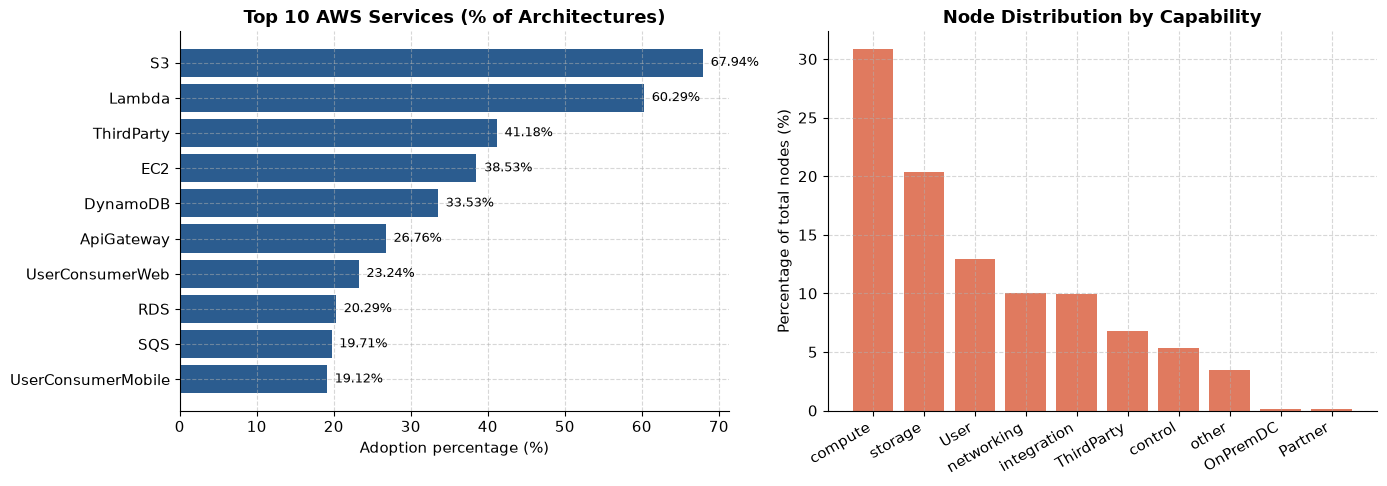

In [10]:
num_archs = dataset.architectures.height
num_unique_services = dataset.nodes.select(pl.col("service").n_unique()).item()
num_aws_services = dataset.nodes.filter(pl.col("is_aws") == True).select(pl.col("service").n_unique()).item()

print(" DATASET MACRO SUMMARY:")
print(f"   • Total analyzable architectures: {num_archs}")
print(f"   • Total unique node/service types: {num_unique_services}")
print(f"   • Unique pure-AWS services identified: {num_aws_services}")

print("\n DESCRIPTIVE STATISTICS OF ARCHITECTURE SIZE:")
stats_archs = dataset.architectures.select([
    pl.col("num_nodes"),
    pl.col("num_edges")
]).describe()
print(stats_archs)

df_service_pop = (
    dataset.nodes
    .group_by("service")
    .agg([
        pl.col("arch_id").n_unique().alias("num_architectures"),
        pl.col("is_aws").first().alias("is_aws"),
        pl.col("capability").first().alias("capability")
    ])
    .with_columns(
        ((pl.col("num_architectures") / num_archs) * 100).round(2).alias("percentage")
    )
    .sort("num_architectures", descending=True)
)

print("\nTOP 15 MOST USED SERVICES:")
print(df_service_pop.head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_10 = df_service_pop.head(10)
services_list = top_10["service"].to_list()[::-1]
pct_list = top_10["percentage"].to_list()[::-1]

axes[0].barh(services_list, pct_list, color="#2b5c8f")
axes[0].set_title("Top 10 AWS Services (% of Architectures)", fontweight="bold")
axes[0].set_xlabel("Adoption percentage (%)")
for i, v in enumerate(pct_list):
    axes[0].text(v + 1, i, f"{v}%", va='center', fontsize=9)

df_cap = (
    dataset.nodes
    .group_by("capability")
    .agg(pl.len().alias("count"))
    .with_columns(((pl.col("count") / dataset.nodes.height) * 100).round(2).alias("pct"))
    .sort("count", descending=True)
)
cap_list = df_cap["capability"].to_list()
cap_pct_list = df_cap["pct"].to_list()

axes[1].bar(cap_list, cap_pct_list, color="#e07a5f")
axes[1].set_title("Node Distribution by Capability", fontweight="bold")
axes[1].set_ylabel("Percentage of total nodes (%)")
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=30, ha="right")

plt.tight_layout()
plt.show()

# ==============================================================================
# SECTION 6: GRAPH MINING AND CLOUD TOPOLOGY
# ==============================================================================

 Distribution of Interaction Types (Edges)[cite: 1]:
shape: (3, 3)
┌─────────┬───────┬────────────┐
│ type    ┆ count ┆ percentage │
│ ---     ┆ ---   ┆ ---        │
│ str     ┆ u32   ┆ f64        │
╞═════════╪═══════╪════════════╡
│ unknown ┆ 14625 ┆ 92.07      │
│ data    ┆ 978   ┆ 6.16       │
│ meta    ┆ 281   ┆ 1.77       │
└─────────┴───────┴────────────┘

 Top 10 Services by Topological Degree (Outgoing vs Incoming Interactions)[cite: 1]:
shape: (10, 5)
┌─────────────────┬──────────────────┬─────────────────┬─────────────────┬──────────────┐
│ source_service  ┆ out_degree_total ┆ target_service  ┆ in_degree_total ┆ total_degree │
│ ---             ┆ ---              ┆ ---             ┆ ---             ┆ ---          │
│ str             ┆ u32              ┆ str             ┆ u32             ┆ u32          │
╞═════════════════╪══════════════════╪═════════════════╪═════════════════╪══════════════╡
│ Lambda          ┆ 2075             ┆ Lambda          ┆ 1990            ┆ 4065      

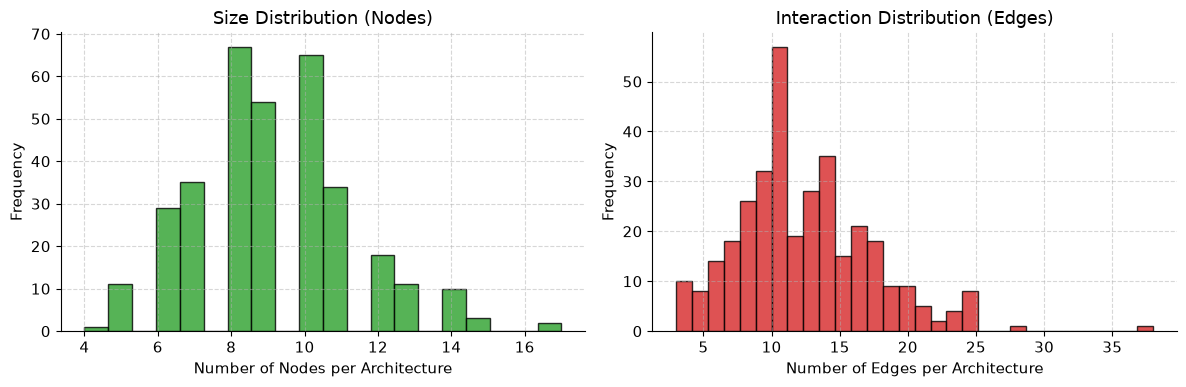

In [11]:
df_edge_types = (
    dataset.edges
    .group_by("type")
    .len(name="count")
    .with_columns(
        ((pl.col("count") / dataset.edges.height) * 100).round(2).alias("percentage")
    )
    .sort("count", descending=True)
)

print(" Distribution of Interaction Types (Edges)[cite: 1]:")
print(df_edge_types)

df_edges_named = (
    dataset.edges
    .join(dataset.nodes.select(["arch_id", "node_id", "service"]),
          left_on=["arch_id", "source"], right_on=["arch_id", "node_id"], how="inner")
    .rename({"service": "source_service"})
    .join(dataset.nodes.select(["arch_id", "node_id", "service"]),
          left_on=["arch_id", "target"], right_on=["arch_id", "node_id"], how="inner")
    .rename({"service": "target_service"})
)

df_writers = (
    df_edges_named
    .group_by("source_service")
    .len(name="out_degree_total")
    .sort("out_degree_total", descending=True)
)

df_readers = (
    df_edges_named
    .group_by("target_service")
    .len(name="in_degree_total")
    .sort("in_degree_total", descending=True)
)

df_topology_roles = (
    df_writers.join(df_readers, left_on="source_service", right_on="target_service", how="full")
    .fill_null(0)
    .with_columns(
        (pl.col("out_degree_total") + pl.col("in_degree_total")).alias("total_degree")
    )
    .sort("total_degree", descending=True)
)

print("\n Top 10 Services by Topological Degree (Outgoing vs Incoming Interactions)[cite: 1]:")
print(df_topology_roles.head(10))

nodes_list = dataset.architectures["num_nodes"].to_list()
edges_list = dataset.architectures["num_edges"].to_list()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(nodes_list, bins=20, color="#2ca02c", edgecolor="black", alpha=0.8)
ax1.set_xlabel("Number of Nodes per Architecture")
ax1.set_ylabel("Frequency")
ax1.set_title("Size Distribution (Nodes)")

ax2.hist(edges_list, bins=30, color="#d62728", edgecolor="black", alpha=0.8)
ax2.set_xlabel("Number of Edges per Architecture")
ax2.set_ylabel("Frequency")
ax2.set_title("Interaction Distribution (Edges)")

plt.tight_layout()
plt.show()

# ==============================================================================
# SECTION 7: RELATIONAL ANALYSIS AND CO-OCCURRENCES (POLARS)
# ==============================================================================

In [12]:
print(" COMPUTING CO-OCCURRENCES AND EMPIRICAL TRANSITION PROBABILITIES...")

arch_services_df = (
    dataset.nodes
    .filter(pl.col("is_aws") == True)
    .group_by("arch_id")
    .agg(pl.col("service").unique().alias("unique_services"))
)

cooc_counter = Counter()
service_arch_count = Counter()

for services_list in arch_services_df["unique_services"].to_list():
    for s in services_list:
        service_arch_count[s] += 1
    for s1, s2 in combinations(sorted(services_list), 2):
        cooc_counter[(s1, s2)] += 1

cooc_records = []
for (s1, s2), count in cooc_counter.items():
    union_count = service_arch_count[s1] + service_arch_count[s2] - count
    jaccard = count / union_count if union_count > 0 else 0.0
    cooc_records.append({
        "service_a": s1,
        "service_b": s2,
        "cooc_frequency": count,
        "jaccard_similarity": round(jaccard, 4)
    })

df_cooccurrences = pl.DataFrame(cooc_records).sort("cooc_frequency", descending=True)
print("\nTop 10 Service Pairs with Highest Undirected Co-occurrence:")
print(df_cooccurrences.head(10))

df_transitions = (
    df_edges_named
    .filter((pl.col("source_service") != pl.col("target_service")))
    .group_by(["source_service", "target_service"])
    .len(name="interaction_count")
    .join(df_writers, on="source_service", how="left")
    .with_columns(
        (pl.col("interaction_count") / pl.col("out_degree_total")).round(4).alias("prob_transition")
    )
    .sort("interaction_count", descending=True)
)

print("\n➡ Top 10 Actual Directed Flows (Transition Probability P(S_j | S_i)):")
print(df_transitions.select(["source_service", "target_service", "interaction_count", "prob_transition"]).head(10))

 COMPUTING CO-OCCURRENCES AND EMPIRICAL TRANSITION PROBABILITIES...

Top 10 Service Pairs with Highest Undirected Co-occurrence:
shape: (10, 4)
┌────────────┬───────────┬────────────────┬────────────────────┐
│ service_a  ┆ service_b ┆ cooc_frequency ┆ jaccard_similarity │
│ ---        ┆ ---       ┆ ---            ┆ ---                │
│ str        ┆ str       ┆ i64            ┆ f64                │
╞════════════╪═══════════╪════════════════╪════════════════════╡
│ Lambda     ┆ S3        ┆ 144            ┆ 0.4932             │
│ DynamoDB   ┆ Lambda    ┆ 92             ┆ 0.4053             │
│ EC2        ┆ S3        ┆ 86             ┆ 0.3116             │
│ DynamoDB   ┆ S3        ┆ 76             ┆ 0.2825             │
│ ApiGateway ┆ Lambda    ┆ 75             ┆ 0.3394             │
│ EC2        ┆ Lambda    ┆ 63             ┆ 0.2308             │
│ ApiGateway ┆ S3        ┆ 56             ┆ 0.2105             │
│ S3         ┆ SQS       ┆ 47             ┆ 0.1873             │
│ RDS      

# ==============================================================================
# SECTION 8: PREPARATION FOR THE PROBABILISTIC MODEL AND OPTIMIZATION
# ==============================================================================

In [13]:
df_services_master = (
    df_service_pop
    .join(df_topology_roles, left_on="service", right_on="source_service", how="left")
    .drop("target_service")
    .fill_null(0)
    .with_columns([
        (pl.col("num_architectures") / pl.col("num_architectures").sum()).round(6).alias("base_prob_weight"),
        (pl.col("out_degree_total") / (pl.col("total_degree") + 1)).round(4).alias("source_sink_ratio")
    ])
    .sort("num_architectures", descending=True)
)
print(df_services_master.select([
    "service", "capability", "num_architectures", "base_prob_weight", "total_degree", "source_sink_ratio"
]).head(10))

G_cooc_master = nx.Graph()
for row in df_cooccurrences.iter_rows(named=True):
    if row["cooc_frequency"] >= COOC_THRESHOLD:
        G_cooc_master.add_edge(
            row["service_a"],
            row["service_b"],
            weight=row["cooc_frequency"],
            jaccard=row["jaccard_similarity"]
        )

print(f"\n️ Master Co-occurrence Graph built: {G_cooc_master.number_of_nodes()} nodes, {G_cooc_master.number_of_edges()} significant edges.")

shape: (10, 6)
┌─────────────────┬─────────────┬─────────────────┬────────────────┬──────────────┬────────────────┐
│ service         ┆ capability  ┆ num_architectur ┆ base_prob_weig ┆ total_degree ┆ source_sink_ra │
│ ---             ┆ ---         ┆ es              ┆ ht             ┆ ---          ┆ tio            │
│ str             ┆ str         ┆ ---             ┆ ---            ┆ u32          ┆ ---            │
│                 ┆             ┆ u32             ┆ f64            ┆              ┆ f64            │
╞═════════════════╪═════════════╪═════════════════╪════════════════╪══════════════╪════════════════╡
│ S3              ┆ storage     ┆ 231             ┆ 0.087833       ┆ 3350         ┆ 0.4628         │
│ Lambda          ┆ compute     ┆ 205             ┆ 0.077947       ┆ 4065         ┆ 0.5103         │
│ ThirdParty      ┆ ThirdParty  ┆ 140             ┆ 0.053232       ┆ 1745         ┆ 0.4937         │
│ EC2             ┆ compute     ┆ 131             ┆ 0.04981        ┆ 2483   

# ==============================================================================
# SECTION 9: PROJECT STATE EXPORT AND PRESERVATION
# ==============================================================================

In [14]:
OUTPUT_DIR = BASE_DIR / "output_analytics"
OUTPUT_DIR.mkdir(exist_ok=True)

dataset.architectures.write_parquet(OUTPUT_DIR / "cloudscape_architectures.parquet")
dataset.nodes.write_parquet(OUTPUT_DIR / "cloudscape_nodes.parquet")
dataset.edges.write_parquet(OUTPUT_DIR / "cloudscape_edges.parquet")

df_services_master.write_csv(OUTPUT_DIR / "services_master_optimization.csv")
df_cooccurrences.write_csv(OUTPUT_DIR / "services_cooccurrences.csv")
df_transitions.write_csv(OUTPUT_DIR / "services_transitions.csv")

dataset.architectures.with_columns(
    pl.col("category_list").list.join(", ")
).write_csv(OUTPUT_DIR / "cloudscape_architectures.csv")

print(f"    Analytical tables exported to Parquet/CSV in folder: '{OUTPUT_DIR}'")

bundle_path = OUTPUT_DIR / "cloudscape_pipeline_bundle.pkl"
bundle_data = {
    "dataset": dataset,
    "df_services_master": df_services_master,
    "df_cooccurrences": df_cooccurrences,
    "df_transitions": df_transitions,
    "G_cooc_master": G_cooc_master
}

with open(bundle_path, "wb") as f:
    pickle.dump(bundle_data, f)

print(f"    Master binary bundle exported successfully at: '{bundle_path.name}'")

    Analytical tables exported to Parquet/CSV in folder: 'output_analytics'
    Master binary bundle exported successfully at: 'cloudscape_pipeline_bundle.pkl'
